# Assignment 10 Decision Tree Induction(Iris Dataset)
## Date: 1/10/2026



In [19]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import (SelectKBest,f_classif,mutual_info_classif)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)

In [20]:
iris = load_iris()
X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)
y = pd.Series(
    iris.target,
    name="target"
)
print("Dataset Shape:", X.shape)
print("\nFeatures:")
print(X.columns.tolist())
print("\nFirst 5 rows:")
print(X.head())

Dataset Shape: (150, 4)

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [21]:
print("\n========== DATA INFORMATION ==========")
print(X.info())
print("\n========== STATISTICS ==========")
print(X.describe())
print("\n========== MISSING VALUES ==========")
print(X.isnull().sum())
print("\n========== DUPLICATES ==========")
print("Number of duplicate rows:", X.duplicated().sum())


========== DATA INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None

========== STATISTICS ==========
       sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
count         150.000000        150.000000         150.000000        150.000000
mean            5.843333          3.057333           3.758000          1.199333
std             0.828066          0.435866           1.765298          0.762238
min             4.300000          2.000000           1.000000          0.100000
25%             5.100000          2.800000           1.600000          0.300000
50%      

In [22]:
data = X.copy()
data["target"] = y
data = data.drop_duplicates()
X = data.drop("target", axis=1)
y = data["target"]
print("\nShape after removing duplicates:", X.shape)


Shape after removing duplicates: (149, 4)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 119
Testing samples: 30


In [24]:
imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)
print("\nMissing values after imputation:")
print(X_train_imputed.isnull().sum())


Missing values after imputation:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64


In [25]:
def find_outliers(df):
    outlier_count = {}
    for column in df.columns:
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ]
        outlier_count[column] = len(outliers)
    return outlier_count
outliers = find_outliers(X_train_imputed)
print("\n========== OUTLIER COUNT ==========")
for feature, count in outliers.items():
    print(feature, ":", count)


========== OUTLIER COUNT ==========
sepal length (cm) : 0
sepal width (cm) : 2
petal length (cm) : 0
petal width (cm) : 0


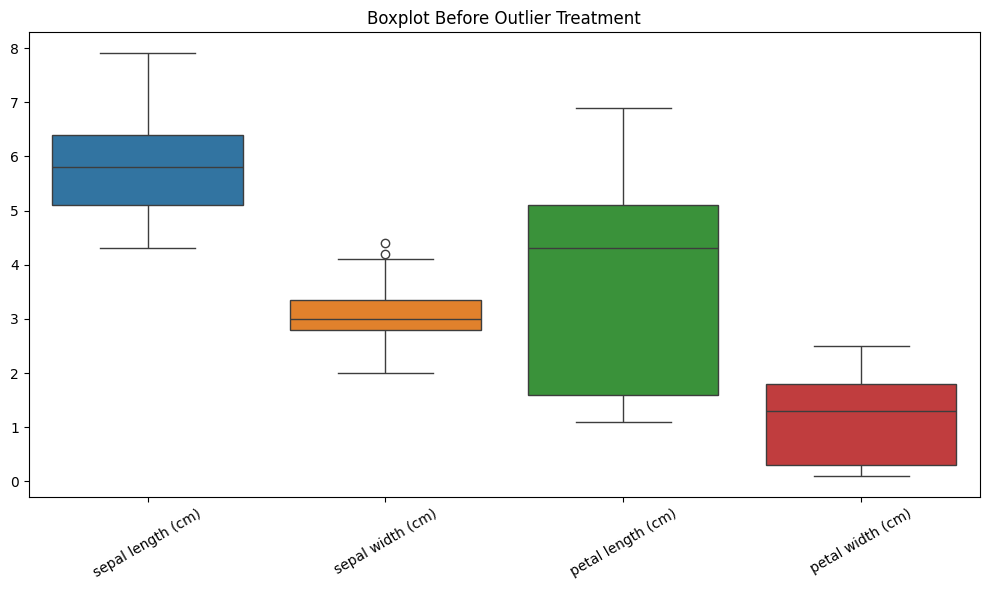

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=X_train_imputed)

plt.xticks(rotation=30)
plt.title("Boxplot Before Outlier Treatment")
plt.tight_layout()
plt.show()

In [27]:
def cap_outliers(train, test):
    train = train.copy()
    test = test.copy()
    for column in train.columns:
        Q1 = train[column].quantile(0.25)
        Q3 = train[column].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        train[column] = train[column].clip(
            lower=lower,
            upper=upper
        )
        test[column] = test[column].clip(
            lower=lower,
            upper=upper
        )
    return train, test
X_train_clean, X_test_clean = cap_outliers(
    X_train_imputed,
    X_test_imputed
)

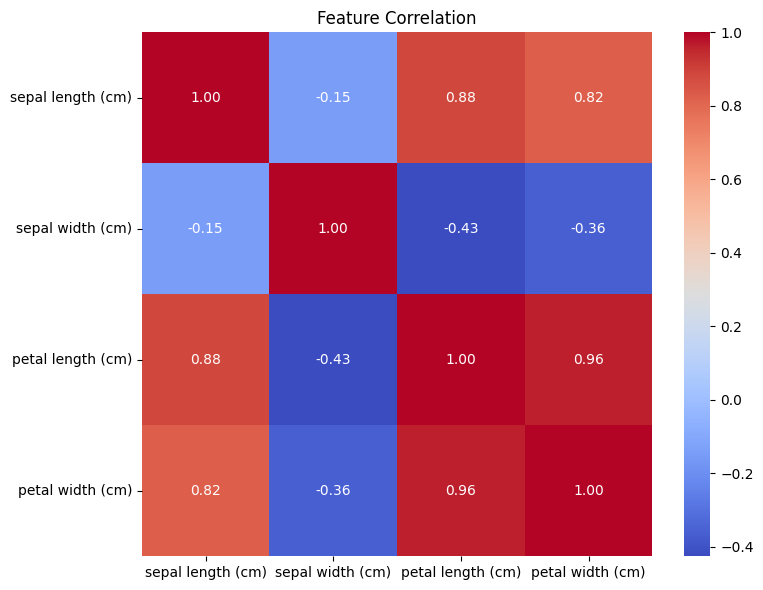

In [28]:
plt.figure(figsize=(8, 6))
correlation = X_train_clean.corr()
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

In [29]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_clean),
    columns=X_train_clean.columns,
    index=X_train_clean.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_clean),
    columns=X_test_clean.columns,
    index=X_test_clean.index
)
print("\n========== SCALED FEATURES ==========")
print(X_train_scaled.head())


========== SCALED FEATURES ==========
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
6            -1.501587          0.784098          -1.339093         -1.179737
128           0.639824         -0.589757           1.041834          1.186365
95           -0.192947         -0.131805           0.248192          0.003314
44           -0.906751          1.700002          -1.055649         -1.048287
30           -1.263653          0.097170          -1.225715         -1.311187


In [30]:
k = 2
selector_anova = SelectKBest(
    score_func=f_classif,
    k=k
)
X_train_anova = selector_anova.fit_transform(
    X_train_scaled,
    y_train
)
X_test_anova = selector_anova.transform(
    X_test_scaled
)
selected_anova = X_train_scaled.columns[
    selector_anova.get_support()
]
print("\n========== ANOVA FEATURE SELECTION ==========")
print("Selected features:")
for feature in selected_anova:
    print(feature)
print("\nFeature scores:")
anova_scores = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Score": selector_anova.scores_,
    "P_Value": selector_anova.pvalues_
})
print(
    anova_scores.sort_values(
        by="Score",
        ascending=False
    )
)


========== ANOVA FEATURE SELECTION ==========
Selected features:
petal length (cm)
petal width (cm)

Feature scores:
             Feature       Score       P_Value
2  petal length (cm)  944.319333  1.661382e-72
3   petal width (cm)  800.387058  1.334137e-68
0  sepal length (cm)  101.353582  3.482070e-26
1   sepal width (cm)   42.803642  1.194545e-14


In [31]:
mi_scores = mutual_info_classif(
    X_train_scaled,
    y_train,
    random_state=42
)
mi_results = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "MI_Score": mi_scores
})
mi_results = mi_results.sort_values(
    by="MI_Score",
    ascending=False
)
print("\n========== MUTUAL INFORMATION ==========")
print(mi_results)


========== MUTUAL INFORMATION ==========
             Feature  MI_Score
3   petal width (cm)  1.005330
2  petal length (cm)  1.000550
0  sepal length (cm)  0.551755
1   sepal width (cm)  0.257839


In [32]:
best_features_mi = mi_results.head(2)["Feature"].tolist()
print("\nBest features according to Mutual Information:")
print(best_features_mi)


Best features according to Mutual Information:
['petal width (cm)', 'petal length (cm)']


In [33]:

X_train_final = X_train_scaled[
    best_features_mi
]
X_test_final = X_test_scaled[
    best_features_mi
]
print("\n========== FINAL DATA ==========")
print("Selected features:")
print(best_features_mi)
print("\nTraining shape:")
print(X_train_final.shape)
print("\nTesting shape:")
print(X_test_final.shape)
print("\nFinal training data:")
print(X_train_final.head())


========== FINAL DATA ==========
Selected features:
['petal width (cm)', 'petal length (cm)']

Training shape:
(119, 2)

Testing shape:
(30, 2)

Final training data:
     petal width (cm)  petal length (cm)
6           -1.179737          -1.339093
128          1.186365           1.041834
95           0.003314           0.248192
44          -1.048287          -1.055649
30          -1.311187          -1.225715


In [34]:
print("Selected Features:")
print(best_features_mi)
print("\nTraining Shape:", X_train_final.shape)
print("Testing Shape:", X_test_final.shape)

Selected Features:
['petal width (cm)', 'petal length (cm)']

Training Shape: (119, 2)
Testing Shape: (30, 2)


In [35]:
dt_model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=3,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

In [36]:
dt_model.fit(
    X_train_final,
    y_train
)

DecisionTreeClassifier(criterion='entropy', max_depth=3, min_samples_leaf=5,
                       min_samples_split=10, random_state=42)

In [37]:
y_train_pred = dt_model.predict(
    X_train_final
)
train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

In [38]:
y_test_pred = dt_model.predict(
    X_test_final
)
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

In [39]:
print("Training Accuracy:", train_accuracy)
print("Testing Accuracy :", test_accuracy)

Training Accuracy: 0.9663865546218487
Testing Accuracy : 0.9333333333333333


In [40]:
accuracy_difference = train_accuracy - test_accuracy
print(
    "\nTraining - Testing Accuracy Difference:",
    accuracy_difference
)
if accuracy_difference > 0.10:
    print("Warning: Model may be overfitting.")
else:
    print("Training and testing performance are reasonably close.")


Training - Testing Accuracy Difference: 0.0330532212885154
Training and testing performance are reasonably close.


In [41]:
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



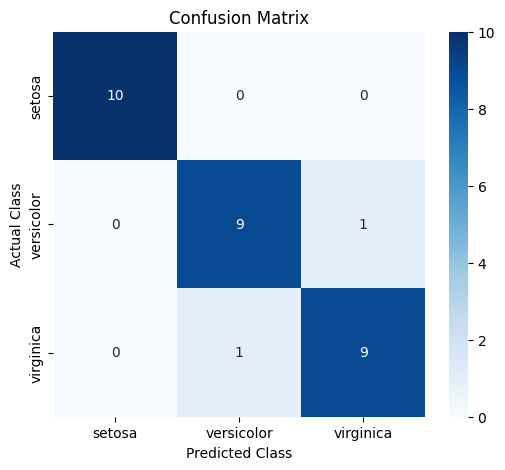

In [42]:
cm = confusion_matrix(
    y_test,
    y_test_pred
)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [43]:
cv_scores = cross_val_score(
    dt_model,
    X_train_final,
    y_train,
    cv=5,
    scoring="accuracy"
)
print("\n========== 5-FOLD CROSS VALIDATION ==========")
print("CV Scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("CV Standard Deviation:", cv_scores.std())


========== 5-FOLD CROSS VALIDATION ==========
CV Scores: [0.91666667 0.95833333 0.91666667 0.95833333 0.95652174]
Mean CV Accuracy: 0.941304347826087
CV Standard Deviation: 0.020127455670045178
